In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds

from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Reproducibility
SEED = 42
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("TensorFlow Datasets:", tfds.__version__)
print("Devices:", tf.config.list_physical_devices())

TensorFlow: 2.21.0
TensorFlow Datasets: 4.9.10
Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


**Windows GPU note:** Native Windows installations of TensorFlow 2.11+ generally run on CPU unless configured through a supported alternative such as WSL2. This project is small enough to run on CPU. A GPU warning does not mean the model has failed.

In [2]:
(train_raw, val_raw, test_raw), dataset_info = tfds.load(
    "tf_flowers",
    split=[
        "train[:80%]",
        "train[80%:90%]",
        "train[90%:]"
    ],
    as_supervised=True,
    with_info=True
)

class_names = dataset_info.features["label"].names
NUM_CLASSES = len(class_names)

print("Dataset:", dataset_info.name)
print("Total images:", dataset_info.splits["train"].num_examples)
print("Number of classes:", NUM_CLASSES)
print("Classes:", class_names)

Dataset: tf_flowers
Total images: 3670
Number of classes: 5
Classes: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']


In [3]:
IMG_SIZE = 64
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def preprocess_image(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

train_data = (
    train_raw
    .map(preprocess_image, num_parallel_calls=AUTOTUNE)
    .shuffle(1000, seed=SEED, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_data = (
    val_raw
    .map(preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_data = (
    test_raw
    .map(preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Training, validation and test datasets are ready.")

Training, validation and test datasets are ready.


Batch shape: (32, 64, 64, 3)
One image shape: (64, 64, 3)
Pixel range: 0.0 to 1.0


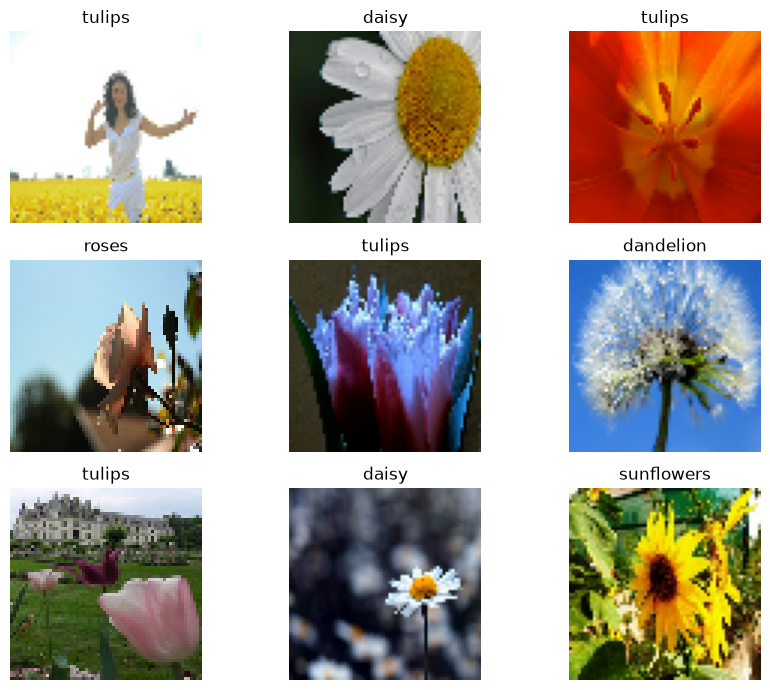

In [4]:
for images, labels in train_data.take(1):
    print("Batch shape:", images.shape)
    print("One image shape:", images[0].shape)
    print("Pixel range:", float(tf.reduce_min(images)), "to", float(tf.reduce_max(images)))

    plt.figure(figsize=(9, 7))
    for i in range(min(9, images.shape[0])):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy())
        plt.title(class_names[int(labels[i].numpy())])
        plt.axis("off")
    plt.tight_layout()
    plt.show()

In [5]:
model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    # Data augmentation
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),

    # Convolution block 1
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 2
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 3
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification head
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.25),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)             │ (None, 64, 64, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_rotation (RandomRotation)     │ (None, 64, 64, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_zoom (RandomZoom)             │ (None, 64, 64, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 62, 62, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 31, 31, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 29, 29, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 14, 14, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 12, 12, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 6, 6, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 5)                   │             645 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 110,405 (431.27 KB)

 Trainable params: 110,405 (431.27 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


In [7]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-5,
    verbose=1
)

EPOCHS = 25

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=EPOCHS,
    callbacks=[early_stop, reduce_lr],
    shuffle=False
)

Epoch 1/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 6s 48ms/step - accuracy: 0.3781 - loss: 1.3759 - val_accuracy: 0.4441 - val_loss: 1.2172 - learning_rate: 0.0010
Epoch 2/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.4864 - loss: 1.2124 - val_accuracy: 0.5395 - val_loss: 1.1179 - learning_rate: 0.0010
Epoch 3/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.5279 - loss: 1.1309 - val_accuracy: 0.4741 - val_loss: 1.2878 - learning_rate: 0.0010
Epoch 4/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.5616 - loss: 1.0693
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - accuracy: 0.5616 - loss: 1.0693 - val_accuracy: 0.5368 - val_loss: 1.1291 - learning_rate: 0.0010
Epoch 5/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.5991 - loss: 1.0148 - val_accuracy: 0.5722 - val_loss: 1.0737 - learning_rate: 5.0000e-04
Epoch 6/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.6182 - loss: 0.9764 - val_

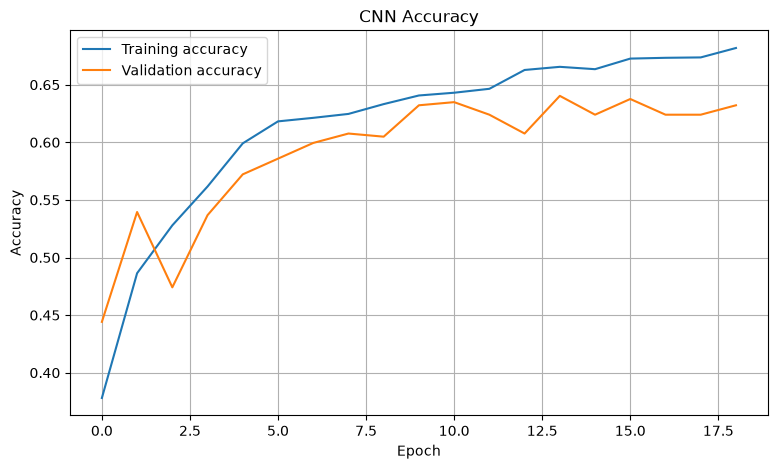

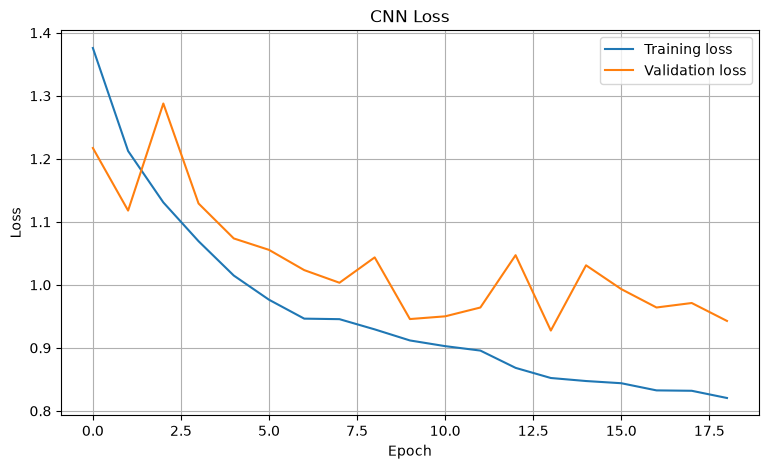

Best validation-loss epoch: 14
Best validation accuracy: 64.03%


In [8]:
plt.figure(figsize=(9, 5))
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Loss")
plt.legend()
plt.grid(True)
plt.show()

best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print("Best validation-loss epoch:", best_epoch)
print("Best validation accuracy: {:.2f}%".format(max(history.history["val_accuracy"]) * 100))

In [9]:
test_loss, test_accuracy = model.evaluate(test_data, verbose=1)

print("\\nFinal test results")
print("------------------")
print("Test accuracy: {:.2f}%".format(test_accuracy * 100))
print("Test loss: {:.4f}".format(test_loss))

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.6267 - loss: 0.8805
\nFinal test results
------------------
Test accuracy: 62.67%
Test loss: 0.8805


              precision    recall  f1-score   support

   dandelion       0.76      0.46      0.57        70
       daisy       0.56      0.82      0.66        61
      tulips       0.54      0.68      0.60        85
  sunflowers       0.73      0.88      0.80        76
       roses       0.66      0.31      0.42        75

    accuracy                           0.63       367
   macro avg       0.65      0.63      0.61       367
weighted avg       0.65      0.63      0.61       367



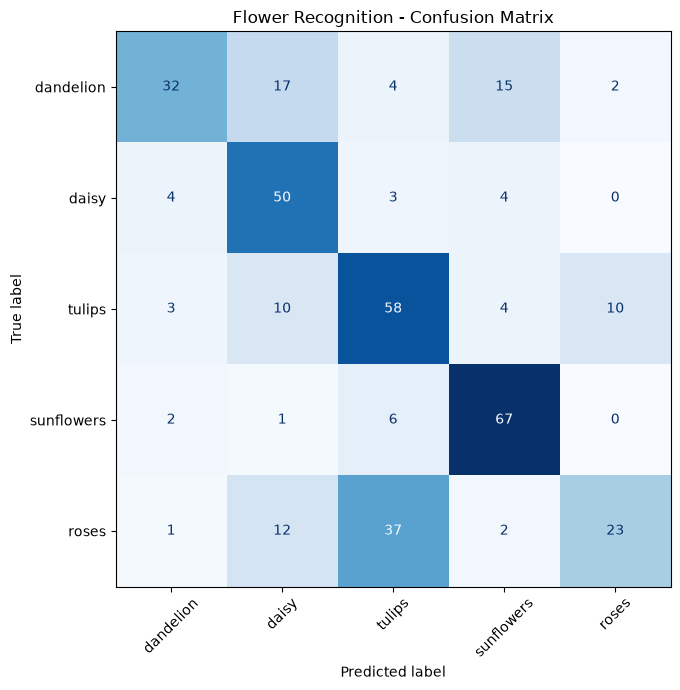

In [10]:
y_true = []
y_pred = []

for images, labels in test_data:
    probabilities = model.predict(images, verbose=0)
    predictions = np.argmax(probabilities, axis=1)
    y_true.extend(labels.numpy().tolist())
    y_pred.extend(predictions.tolist())

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
fig, ax = plt.subplots(figsize=(8, 7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap="Blues", values_format="d", xticks_rotation=45, colorbar=False)
plt.title("Flower Recognition - Confusion Matrix")
plt.tight_layout()
plt.show()

In [11]:
from tensorflow.keras.utils import load_img, img_to_array

# Example: image_path = r"C:\\Users\\asjad\\Pictures\\rose.jpg"
image_path = ""

if image_path and os.path.isfile(image_path):
    img = load_img(image_path, target_size=(IMG_SIZE, IMG_SIZE))
    img_array = img_to_array(img).astype("float32") / 255.0
    img_batch = np.expand_dims(img_array, axis=0)

    probabilities = model.predict(img_batch, verbose=0)[0]
    predicted_index = int(np.argmax(probabilities))
    predicted_flower = class_names[predicted_index]
    confidence = float(probabilities[predicted_index]) * 100

    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"{predicted_flower} ({confidence:.1f}% model confidence)")
    plt.show()

    print("Predicted flower:", predicted_flower)
    print("Model confidence: {:.2f}%".format(confidence))
elif image_path:
    print("Image path not found. Check the path and try again.")
else:
    print("Prediction skipped. Set image_path to a flower image to try a prediction.")

Prediction skipped. Set image_path to a flower image to try a prediction.


In [12]:
model.save("flower_recognition_cnn.keras")
print("Saved model: flower_recognition_cnn.keras")

Saved model: flower_recognition_cnn.keras
